# Why Rebuild a Walking Robot Duck in Modelica?

MuJoCo trains the [Pollen Robotics and Hugging Face Microduck](https://www.youtube.com/watch?v=Nt6d62vN7CU) walking policy fast, using a Python callback before every `mj_step` with a fixed supply voltage per episode, 14 extra 3D hinges to mimic 2° of gear play, and a contact law compiled into the C solver. Rebuilding the robot in Modelica puts the 3D multibody tree, the 1D drivetrains, the 2S lithium-ion battery pack (`useBattery = true`), the two-node servo thermal network (`useThermal = true`) and the sole contact equations (`PointContact`) in one declarative plant, exported as `DuckPlant.fmu`.

- **Article:** [Why Rebuild a Walking Robot Duck in Modelica?](https://nouseng.co/libraries/atelier/microduck/why-modelica/)
- **Modelica library (`MicroDuck` & `MicroDuckTest`):** [`nouseng/libraries/RoboticsAtelier/MicroDuck`](https://github.com/nouseng/libraries/tree/main/RoboticsAtelier/MicroDuck)
- **MuJoCo robot model & meshes (`mujoco/model/`):** [`pollen-robotics/microduck_rl`](https://github.com/pollen-robotics/microduck_rl) (Apache-2.0)
- **Trained walking policy (`mujoco/velstand.onnx`):** [`pollen-robotics/microduck-policies`](https://huggingface.co/pollen-robotics/microduck-policies) (Apache-2.0)
- **Identified XL330 servo model:** [`Rhoban/bam`](https://github.com/Rhoban/bam) (Apache-2.0)
- **Setup and files:** [README.md](README.md)

In [1]:
from common import *  # FMU and MuJoCo helpers, plot style

## Verify before adding anything

Same policy, same 0.3 m/s forward command, two simulators. The FMU walk takes about 7 s in Python for a 6 s walk, and MuJoCo takes under a second.

In [2]:
duck = walk_fmu()
mj = walk_mujoco(speed_command=0.3)
print(f"MicroDuck library {speed(duck):.3f} m/s, MuJoCo {speed(mj):.3f} m/s over the last 4 s")
print(f"distance after 6 s: {duck['distance'].iloc[-1]:.3f} m against {mj['distance'].iloc[-1]:.3f} m")
print(f"mean trunk height: {1e3 * duck['trunkHeight'].mean():.1f} mm against {1e3 * mj['trunkHeight'].mean():.1f} mm")

MicroDuck library 0.137 m/s, MuJoCo 0.132 m/s over the last 4 s
distance after 6 s: 0.798 m against 0.799 m
mean trunk height: 118.2 mm against 118.1 mm


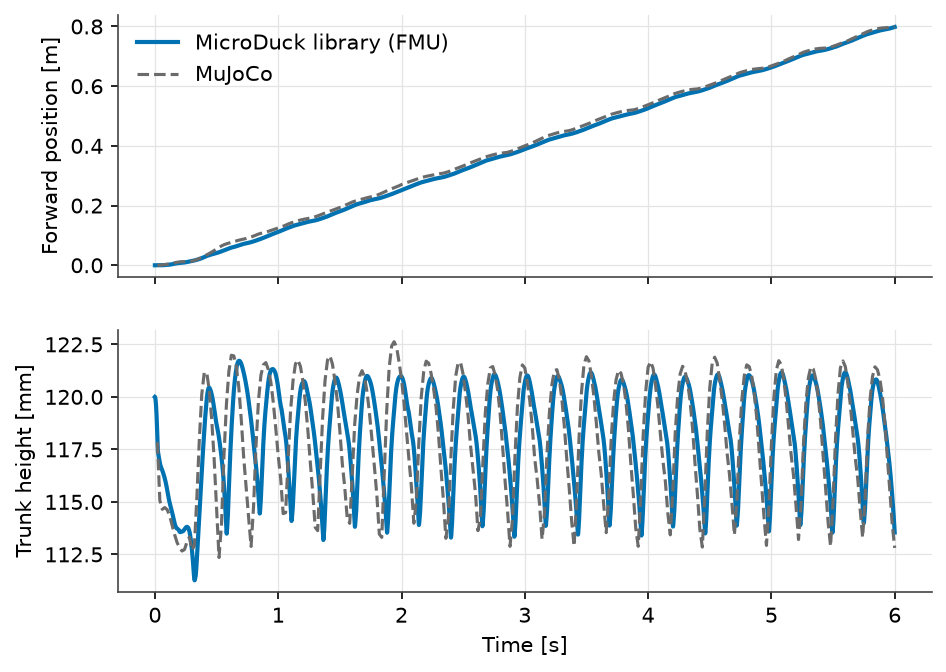

In [3]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(7, 5), sharex=True)
a1.plot(duck["time"], duck["distance"], color=BLUE, label="MicroDuck library (FMU)")
a1.plot(mj["time"], mj["distance"], color=GREY, ls="--", lw=1.5, label="MuJoCo")
a2.plot(duck["time"], 1e3 * duck["trunkHeight"], color=BLUE)
a2.plot(mj["time"], 1e3 * mj["trunkHeight"], color=GREY, ls="--", lw=1.5)
a1.set_ylabel("Forward position [m]"); a1.legend(loc="upper left")
a2.set_ylabel("Trunk height [mm]"); a2.set_xlabel("Time [s]")
plt.show()

## What the plant answers next

### 1. Soft servos used as torque commands

At the walking gain register of 200 (`0.589 N·m/rad` at 7.4 V), the policy swings its angle targets 24° RMS ahead of the knees while staying under 30% of the 1.01 N·m stall torque.

left knee tracking error: 23.8 deg RMS
right knee tracking error: 22.4 deg RMS
peak servo torque: 0.26 N.m (26% of 1.01 N.m stall at 7.4 V)


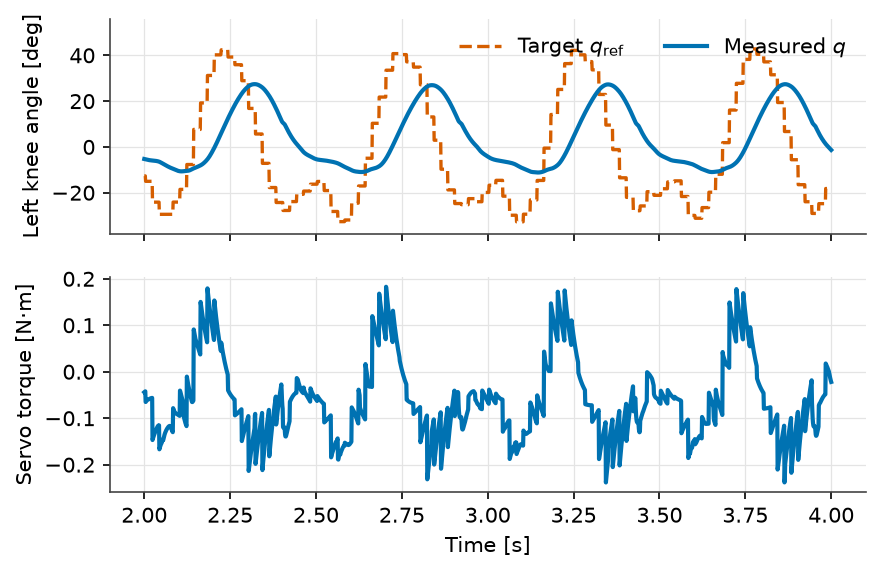

In [4]:
t = duck["time"].to_numpy()
late = t >= 2
win = (t >= 2) & (t <= 4)
q, q_ref, tau = cols(duck, "q"), cols(duck, "qRef"), cols(duck, "servoTorque")
err = np.degrees(q_ref - q)[late]
print(f"left knee tracking error: {np.sqrt((err[:, 3] ** 2).mean()):.1f} deg RMS")
print(f"right knee tracking error: {np.sqrt((err[:, 12] ** 2).mean()):.1f} deg RMS")
print(f"peak servo torque: {np.abs(tau[late]).max():.2f} N.m (26% of 1.01 N.m stall at 7.4 V)")

fig, (a1, a2) = plt.subplots(2, 1, figsize=(6.5, 4.1), sharex=True)
a1.plot(t[win], np.degrees(q_ref[win, 3]), color=ORANGE, ls="--", lw=1.6, label="Target $q_{\\mathrm{ref}}$")
a1.plot(t[win], np.degrees(q[win, 3]), color=BLUE, label="Measured $q$")
a1.set_ylim(-38, 62); a1.set_ylabel("Left knee angle [deg]"); a1.legend(loc="upper right", ncol=2)
a2.plot(t[win], tau[win, 3], color=BLUE); a2.set_ylabel("Servo torque [N·m]"); a2.set_xlabel("Time [s]")
plt.show()

### 2. Supply voltage and an unpowered knee

Lowering the pack supply to 6.5 V or disabling the left knee (`walk_fmu(kneeGain=0)`) shifts 83% more copper heating ($R i^2$) onto the opposite right knee.

6.5 V supply: 0.129 m/s, mean servo power 2.02 W
right knee copper loss: 0.41 W healthy -> 0.75 W with unpowered left knee (+83%)


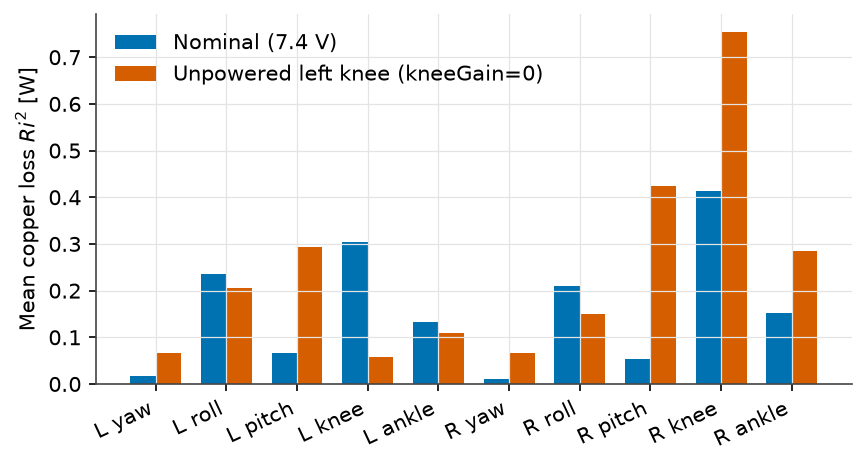

In [5]:
low = walk_fmu(supply=6.5)
limp = walk_fmu(kneeGain=0)
cu_nom = (RESISTANCE * cols(duck, "motorCurrent")[duck["time"] >= 2] ** 2).mean(0)
cu_limp = (RESISTANCE * cols(limp, "motorCurrent")[limp["time"] >= 2] ** 2).mean(0)
print(f"6.5 V supply: {speed(low):.3f} m/s, mean servo power {6.5 * low['batteryCurrent'][low['time'] >= 2].mean():.2f} W")
print(f"right knee copper loss: {cu_nom[12]:.2f} W healthy -> {cu_limp[12]:.2f} W with unpowered left knee (+{(cu_limp[12] / cu_nom[12] - 1) * 100:.0f}%)")

leg_idx = [0, 1, 2, 3, 4, 9, 10, 11, 12, 13]
labels = ["L yaw", "L roll", "L pitch", "L knee", "L ankle", "R yaw", "R roll", "R pitch", "R knee", "R ankle"]
x_pos = np.arange(len(leg_idx))
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.bar(x_pos - 0.18, cu_nom[leg_idx], 0.36, color=BLUE, label="Nominal (7.4 V)")
ax.bar(x_pos + 0.18, cu_limp[leg_idx], 0.36, color=ORANGE, label="Unpowered left knee (kneeGain=0)")
ax.set_xticks(x_pos, labels, rotation=25, ha="right"); ax.set_ylabel("Mean copper loss $Ri^2$ [W]"); ax.legend(loc="upper left")
plt.show()